let's choose the approach where we built a cache, of rows.
- N neurons to pick from
- M spikers, each spiking with probability p
- size of a cache k

- for single unit, probability we will not pick an integer is (N - k) / N
- we pick with probability p, so chance that we will not pick an integer that is in cache is (1-p) + p * (N - k)/ N = 1 - p * k / N
- The probability that M independent pickers will not pick anything is (1 - p * k / N) ^ M 
- probability we will select something is 1 - (1 - p * k / N) ^ M

In [13]:
from math import ceil
p = 0.2
N = 4096
k = 8
M = ceil(N / 16)

print(f"Cache memory required : {k * N} bits")

print(f"probability we will have a cache hit : {(1 - (1 - p * k / N)**M) * 100 }%")

Cache memory required : 32768 bits
probability we will have a cache hit : 9.518025900077332%


# Can we use fixed floating point

In [25]:
from math import log

THLD_MAX = 8e4
alpha = 2.5e4 / THLD_MAX 
THLD_DELTA = 2e-3
MAX_ITER = 1e10

smallest_rand = 0.0
largest_rand = 1.0

thld_start = THLD_DELTA
thld_end = MAX_ITER * THLD_DELTA
eps = 1e-6

def approx(x):
    return THLD_MAX / x + 0.5 - x / (12 * THLD_MAX)

def exact(x):
    return 1 / log(1 + x / THLD_MAX)


noisethld_start_smallest = alpha*log(2.5*smallest_rand+eps) * exact(thld_start)
noisethld_start_largest = alpha*log(2.5*largest_rand+eps) * exact(thld_start)

noisethld_end_smallest = alpha*log(2.5*smallest_rand+eps) * exact(thld_end)
noisethld_end_largest = alpha*log(2.5*largest_rand+eps) * exact(thld_end)

print(f"start : {noisethld_start_smallest}-{noisethld_end_smallest}")
print(f"end : {noisethld_end_smallest}-{noisethld_end_largest}")

start : -172693883.64893922--0.7813562248966004
end : -0.7813562248966004-0.05182217310779256


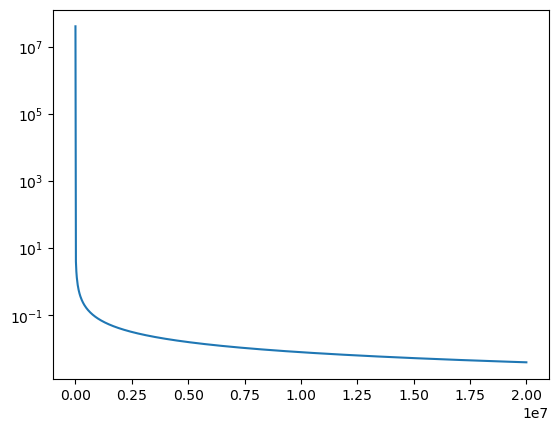

In [27]:
import matplotlib.pyplot as plt 
import numpy as np

x = np.linspace(thld_start, thld_end, 1000)

plt.plot(x, THLD_MAX / x)
plt.yscale("log")
plt.show()

# See the toy problem

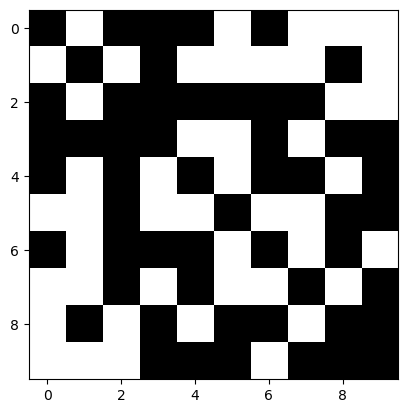

In [3]:
import numpy as np 
import matplotlib.pyplot as plt 


x = np.load("toy.npy")
plt.imshow(x, cmap="gray")